# 1. Is there a short-horizon signal in the BTCUSDT order book?

We forecast the 5-second mid-price return of the Bybit BTCUSDT perpetual from order-book and trade flow, then test the forecast on data that played no part in building it.

**Data.** Bybit's free public archives: the top-200 order book (a snapshot followed by deltas, conflated to about 100 ms) and every trade. `data/manifest.csv` lists the URL, size and SHA-256 of each file.

| period | days | role |
|---|---|---|
| 2025-10-01 – 10-30 | 30 | training (fold 1) |
| 2025-10-31 – 11-09 | 10 | two forward validation folds; final refit on all 40 days |
| 2025-11-10 – 11-29 | 20 | **first sealed test** (this notebook and notebook 2) |
| 2025-12-01 – 2026-01-14 | 45 | **second sealed test**, downloaded only after the execution study was frozen (notebook 3) |

**Timing.** A decision at second $t_k$ with market-data delay $d$ sees only book messages stamped strictly before $t_k - d$ and trades strictly before it (`orderflow/book.py`, tested in `tests/test_book.py`). The model uses $d = 100$ ms.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':      # paths below are relative to the repository root
    os.chdir('..')
sys.path.insert(0, os.getcwd())
import csv
import json
import numpy as np
import matplotlib.pyplot as plt
from orderflow import stats

def read_csv(name):
    with open('results/' + name) as f:
        return list(csv.DictReader(f))

S = json.load(open('results/summary.json'))           # every number quoted in the README
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

with open('data/manifest.csv') as f:
    man = list(csv.DictReader(f))
print(f"{len(man)} raw files, {len({r['date'] for r in man})} days, {sum(int(r['bytes']) for r in man) / 1e9:.1f} GB")

210 raw files, 105 days, 30.3 GB


## A first look at the data

One hour of a training day (Oct 15, 14:00–15:00 UTC) on the one-second grid. The tests never look at the test periods this way.

spread: median 0.009 bp; 5 s return: std 2.70 bp; trades per second: median 27


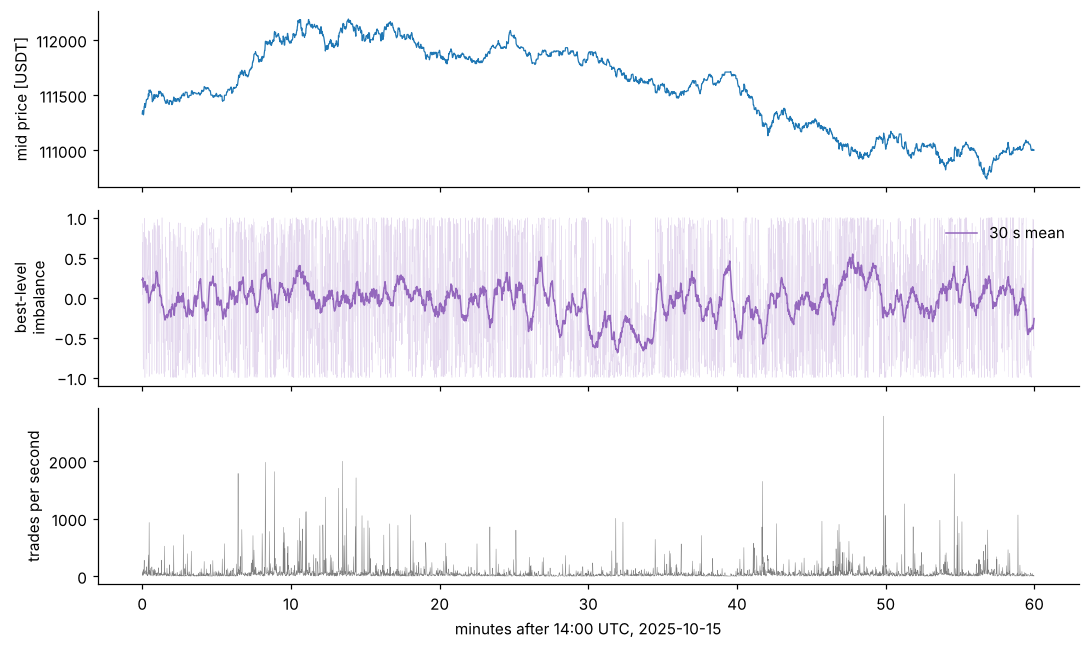

In [2]:
h = np.load('results/sample_hour.npz')
names = list(h['feature_names'])
col = lambda name: h['features'][:, names.index(name)]
t = np.arange(len(h['mid_usdt'])) / 60
fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
ax[0].plot(t, h['mid_usdt'], lw=0.8)
ax[0].set_ylabel('mid price [USDT]')
x = col('imb_l1')
ok_x = np.isfinite(x)
smooth = np.convolve(np.where(ok_x, x, 0), np.ones(30), 'same') / np.maximum(np.convolve(ok_x, np.ones(30), 'same'), 1)
ax[1].plot(t, x, lw=0.3, color='tab:purple', alpha=0.25)
ax[1].plot(t, smooth, lw=1, color='tab:purple', label='30 s mean')
ax[1].legend(frameon=False, loc='upper right')
ax[1].set_ylabel('best-level\nimbalance')
ax[2].plot(t, np.expm1(col('log_trades')), lw=0.3, color='tab:gray')
ax[2].set_ylabel('trades per second')
ax[2].set_xlabel('minutes after 14:00 UTC, 2025-10-15')
fig.tight_layout()
fig.savefig('figures/sample_hour.png')
ok = h['eligible']
print(f"spread: median {np.median(col('spread_bp')[ok]):.3f} bp; 5 s return: std {np.nanstd(h['y']):.2f} bp; "
      f"trades per second: median {np.median(np.expm1(col('log_trades')[ok])):.0f}")

Does the book say anything about the next five seconds? We pool the usable seconds of all 40 training days, sort them into deciles of a feature and plot the mean 5-second return in each decile (bars: ±2 standard errors).

imb_l1: mean 5 s return -0.446 bp in the lowest decile, +0.447 bp in the highest
ofi_norm: mean 5 s return -0.255 bp in the lowest decile, +0.260 bp in the highest


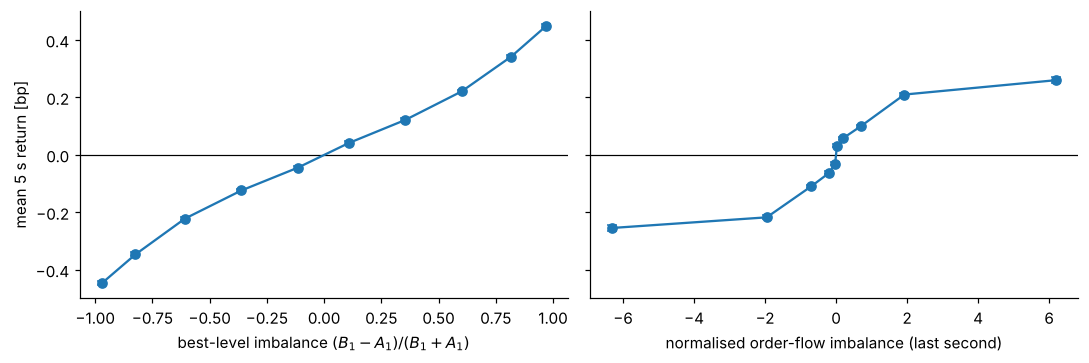

In [3]:
bins = read_csv('imbalance_bins.csv')
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for a, name, label in ((ax[0], 'imb_l1', 'best-level imbalance $(B_1 - A_1)/(B_1 + A_1)$'),
                       (ax[1], 'ofi_norm', 'normalised order-flow imbalance (last second)')):
    r = [x for x in bins if x['feature'] == name]
    x, m, se = (np.array([float(v[k]) for v in r]) for k in ('mean_x', 'mean_y_bp', 'se_y_bp'))
    a.errorbar(x, m, yerr=2 * se, fmt='o-', capsize=3)
    a.axhline(0, color='k', lw=0.8)
    a.set_xlabel(label)
    print(f"{name}: mean 5 s return {m[0]:+.3f} bp in the lowest decile, {m[-1]:+.3f} bp in the highest")
ax[0].set_ylabel('mean 5 s return [bp]')
fig.tight_layout()
fig.savefig('figures/imbalance_vs_return.png')

Both relations are monotone. When the best bid holds much more size than the best ask, the mid tends to rise over the next five seconds, and the reverse. Imbalance is the strongest single feature: the mean 5-second return moves from about −0.45 bp to +0.45 bp across its deciles. That is the signal, and it is already clear how small it is next to an 11 bp round-trip taker fee.

The OFI curve has a different shape: steep near zero and almost flat beyond about ±2 (an S-shape, consistent with the concave price impact seen across markets). OFI is also fat-tailed, so a straight line through these points is pulled flat by the extremes. This matters for the OFI benchmark below.

## Features, target and model

Each second we compute eight features from the visible book (`orderflow/features.py`); $B_1, A_1$ are best bid/ask sizes, $B_5, A_5$ the sizes over five levels and $m$ the mid:

| feature | definition |
|---|---|
| `ofi_norm` | order-flow imbalance over the last second (Cont, Kukanov and Stoikov 2014) divided by the mean best-level depth |
| `imb_l1`, `imb_l5` | $(B_1 - A_1)/(B_1 + A_1)$ and the same over five levels |
| `tvi` | (buy volume − sell volume) / total volume over the last second |
| `spread_bp` | $10^4 (a - b)/m$ |
| `ret_1s_bp` | $10^4 \ln(m_k / m_{k-1})$ |
| `log_trades` | $\ln(1 + \text{trades in the last second})$ |
| `rv30_bp` | root mean square of the last 30 one-second returns |

The target is $y_k = 10^4 \ln(m_{k+5}/m_k)$ in basis points. A second is used only if all eight features are defined and the book was valid throughout. Seconds within 120 s of a split boundary are removed so that no label crosses into the next period.

The forecast is a ridge regression on z-scored features,
$$\hat\beta = \arg\min_\beta \tfrac1n \lVert y - \bar y - X_s\beta\rVert^2 + \lambda\lVert\beta\rVert^2 ,$$
with $\lambda$ chosen by mean daily validation MSE over two forward folds. With 3.4 million training rows and eight well-conditioned features (condition number about 80) the penalty has almost nothing to do: the validation MSE is flat in $\lambda$ (next cell), so the selected $\lambda = 0.0001$, the smallest on the grid, makes the model **effectively OLS**. Ridge was chosen in advance as a guard against collinearity between the two imbalance features; the data showed it was not needed. We compare it with two benchmarks: the zero forecast (the price is a martingale), which tests whether there is any signal at all, and a one-variable OFI regression on raw OFI, which asks whether the other features add anything to the best-known single predictor.

In [4]:
val = json.load(open('results/validation.json'))
print('mean validation MSE (bp^2) by lambda:', {k: round(v, 6) for k, v in val['selection']['scores_mean_daily_mse_bp2'].items()})
print('selected lambda:', val['selection']['lambda'])
cols = val['pooled_validation']['columns']
print('\nvalidation days (10)      mean daily MSE   R2 vs zero')
for name in ('zero', 'ofi', 'ridge_0.0001'):
    r = dict(zip(cols, val['pooled_validation'][name]))
    print(f"  {name:22s}  {r['mean_daily_mse_bp2']:.5f}        {r['r2_oos_vs_zero']:.4f}")
sh = val['shuffle_diagnostic']
print('\nshuffled-label control (gain over zero, bp^2):', {f: round(sh[f][1] - sh[f][0], 5) for f in ('fold1', 'fold2')})

model = json.load(open('results/frozen_model.json'))
print('\nfrozen ridge coefficients (z-scored features):')
for f, b in zip(model['features'], model['ridge']['beta']):
    print(f'  {f:11s} {b:+.4f}')

mean validation MSE (bp^2) by lambda: {'0.0001': 3.293236, '0.001': 3.293237, '0.01': 3.293267, '0.1': 3.293795}
selected lambda: 0.0001

validation days (10)      mean daily MSE   R2 vs zero
  zero                    3.37938        0.0000
  ofi                     3.37320        0.0018
  ridge_0.0001            3.29324        0.0255

shuffled-label control (gain over zero, bp^2): {'fold1': 0.00116, 'fold2': 0.00136}

frozen ridge coefficients (z-scored features):
  ofi_norm    +0.0031
  imb_l1      +0.1796
  imb_l5      +0.0950
  tvi         +0.0064
  spread_bp   -0.0030
  ret_1s_bp   +0.0195
  log_trades  +0.0071
  rv30_bp     -0.0084


**What the model learned.** Two features carry almost all the weight: best-level imbalance (+0.18 bp per standard deviation) and five-level imbalance (+0.10). The other six are below 0.02 each, and raw OFI gets essentially zero weight. In practice this is an **order-book imbalance model**: when more size waits on the bid than on the ask, the mid tends to tick up over the next few seconds.

The frozen model is the output of `fit_model.py`. Rerunning it here on all 40 training days, rebuilt from the raw archives with this repository's code, gives back the frozen model:

In [5]:
chk = json.load(open('results/training_check.json'))
for name, v in chk['checks'].items():
    print(f"  {name:22s} {'identical' if v['identical'] else 'max |diff| %.2g' % v['max_abs_diff']}")
assert chk['all_identical']

  lambda scores          identical
  selected lambda        identical
  training rows          identical
  feature means          identical
  feature std devs       identical
  ridge intercept        identical
  ridge coefficients     identical
  OFI model (a, b)       identical
  taker threshold (bp)   identical


Shuffling the labels within each day removes almost all of the gain, so the validation improvement is not an artefact of the fitting procedure.

## First sealed test (Nov 10–29)

For each test day $t$ we compute $D1_t = \mathrm{MSE}_t(\text{zero}) - \mathrm{MSE}_t(\text{ridge})$ and $D2_t = \mathrm{MSE}_t(\text{OFI}) - \mathrm{MSE}_t(\text{ridge})$. The quantities of interest are their means over the $T = 20$ days, $Q_1$ and $Q_2$.

Seconds within a day are strongly dependent, so the **day** is the sampling unit. We use a moving-block bootstrap over days with blocks of 1, 2 and 5 days (2000 resamples each) and a Student-$t$ interval, all at level $1 - 0.05/3$ (Bonferroni over the three test questions). We fixed the rule before opening the test days: a quantity is *robustly positive* only if **all four** intervals lie above zero.

In [6]:
days1 = read_csv('sealed_test_days.csv')
D1 = np.array([float(r['D1']) for r in days1])
D2 = np.array([float(r['D2']) for r in days1])
res = stats.primary(D1, D2, [int(r['lat_100_100_pi']) for r in days1], [int(r['lat_100_100_n']) for r in days1])

for q, name in (('Q1', 'MSE(zero) - MSE(ridge)'), ('Q2', 'MSE(OFI)  - MSE(ridge)')):
    Q = res['quantities'][q]
    print(f"{q} = {name} = {Q['estimate']:.4f} bp^2   -> {Q['classification']}")
    for b in ('1', '2', '5'):
        print(f"     bootstrap, {b}-day blocks: [{res['bootstrap'][b][q][0]:.4f}, {res['bootstrap'][b][q][1]:.4f}]")
    print(f"     t-interval:              [{Q['t_interval'][0]:.4f}, {Q['t_interval'][1]:.4f}]")
print('positive days:', int((D1 > 0).sum()), 'of', len(D1))
print('pooled out-of-sample R2: ridge %.4f, OFI %.4f' % (S['signal']['first_test_r2_pooled']['ridge'], S['signal']['first_test_r2_pooled']['ofi']))

# the same numbers as the original study
assert res['quantities']['Q1']['estimate'] == S['signal']['first_test_gain_vs_zero']['estimate']
assert res['quantities']['Q2']['t_interval'] == S['signal']['first_test_gain_vs_ofi']['t_interval']

Q1 = MSE(zero) - MSE(ridge) = 0.1127 bp^2   -> robustly_positive
     bootstrap, 1-day blocks: [0.1006, 0.1248]
     bootstrap, 2-day blocks: [0.1016, 0.1276]
     bootstrap, 5-day blocks: [0.1025, 0.1307]
     t-interval:              [0.0992, 0.1262]
Q2 = MSE(OFI)  - MSE(ridge) = 0.1026 bp^2   -> robustly_positive
     bootstrap, 1-day blocks: [0.0923, 0.1131]
     bootstrap, 2-day blocks: [0.0931, 0.1155]
     bootstrap, 5-day blocks: [0.0938, 0.1186]
     t-interval:              [0.0910, 0.1142]
positive days: 20 of 20
pooled out-of-sample R2: ridge 0.0227, OFI 0.0020


## Second sealed test (Dec 1 – Jan 14)

The same frozen model, unchanged, on 45 later days. Training ended on Nov 9, so this also tests whether the signal decays over three to nine weeks. $Q_6$ is the mean of $D1_t$ over these days, with the same interval rule (notebook 3 runs the full study; here we only recompute $Q_6$).

Q6 = mean MSE(zero) - MSE(ridge) = 0.0591 bp^2   -> pos
     t-interval: [0.0468, 0.0714]
pooled out-of-sample R2: ridge 0.0224


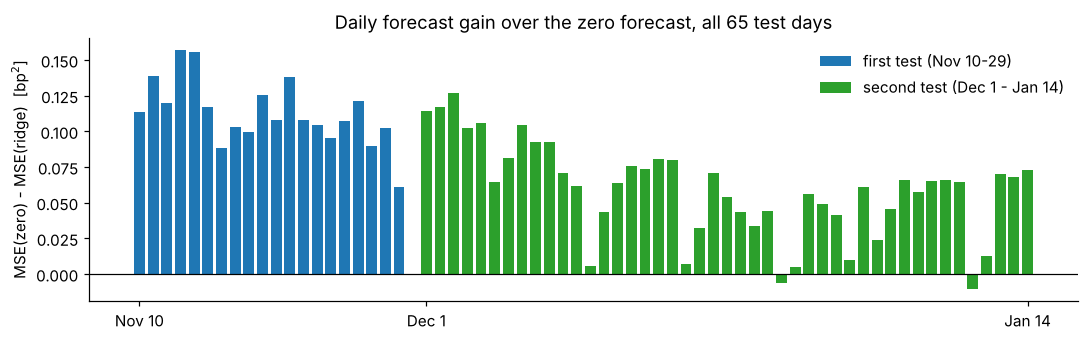

In [7]:
days2 = [{'eligible': int(r['eligible']), 'unresolved_parents': int(r['unresolved_parents']),
          **{k: float(r[k]) for k in ('D4', 'D5', 'D7', 'Q6')}} for r in read_csv('execution_days.csv')]
Q6 = stats.execution_study(days2)['quantities']['Q6']
print(f"Q6 = mean MSE(zero) - MSE(ridge) = {Q6['estimate']:.4f} bp^2   -> {Q6['class']}")
print('     t-interval: [%.4f, %.4f]' % tuple(Q6['t_interval']))
print('pooled out-of-sample R2: ridge %.4f' % S['signal']['second_test_r2_pooled']['ridge'])
assert Q6['estimate'] == S['signal']['second_test_gain_vs_zero']['estimate']

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(20), D1, color='tab:blue', label='first test (Nov 10-29)')
ax.bar(range(21, 66), [d['Q6'] for d in days2], color='tab:green', label='second test (Dec 1 - Jan 14)')
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks([0, 21, 65], ['Nov 10', 'Dec 1', 'Jan 14'])
ax.set_ylabel('MSE(zero) - MSE(ridge)  [bp$^2$]')
ax.set_title('Daily forecast gain over the zero forecast, all 65 test days')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig('figures/daily_forecast_gain.png')

**Reading.** The signal is real: the forecast beats the zero forecast on every interval in both sealed periods, and 63 of the 65 test days show a gain. It also beats the OFI regression, but read that comparison as conservative: the benchmark uses raw OFI linearly, which fits OFI's S-shaped, fat-tailed relation poorly (R² of only 0.2%). A transformed OFI (clipped or squashed) would be a fairer opponent; it was not part of the frozen design and is listed as future work. It is also small: the out-of-sample $R^2$ is about 2.3%, and 2.2% in the later period. The daily MSE gain roughly halves in December–January (0.113 to 0.059 bp$^2$) while $R^2$ barely moves, so the smaller gain mostly reflects smaller 5-second price moves rather than a weaker forecast. Notebook 2 asks whether a signal this small can pay for trading costs.